# Question 1
In the attached text file, you will find the coordinates for 30 potential facility locations and 100
customer locations. The first line in the file gives the numbers of potential facility and customer
locations. The next 30 lines give the (x,y) coordinates of the potential facility locations. The last
100 lines give the (x,y) coordinates of the customer locations. The distance between any two
locations is given by the Euclidean distance. All distances are in miles.

## Resources
### Attached Text file : pmedian_data.txt

### Plot 

In [144]:
import matplotlib.pyplot

# converted code provided in homework to a function

def plotPmedianSolution(xVars, yVars):
    with open("pmedian_data.txt", encoding="utf-8") as file:
        noFacs = int(file.readline().split()[0])
        coordinates = [ [ float(value) for value in line.split() ]
                        for line in file if line.strip() ]

    facilities = coordinates[ : noFacs ]
    customers = coordinates[ noFacs : ]
    noCusts = len(customers)

    assgns = [ 0 for j in range( noCusts ) ]
    for dp in range( noCusts ):
        for fc in range( noFacs ):
            if yVars[ fc , dp ].X > 0.5:
                assgns[ dp ] = fc

    for fc in range( noFacs ):
        if xVars[ fc ].X > 0.5:
            matplotlib.pyplot.plot( facilities[ fc ][ 0 ] , facilities[ fc ][ 1 ] , 'ro' ,
            color = "green" , lw = 9 )
        
    for dp in range( noCusts ):
        matplotlib.pyplot.plot( customers[ dp ][ 0 ] , customers[ dp ][ 1 ] , 'ro' ,
        color = "red" , lw = 9 )
        
    for dp in range( noCusts ):
        dpx = customers[ dp ][ 0 ]
        dpy = customers[ dp ][ 1 ]
        fcx = facilities[ assgns[ dp ] ][ 0 ]
        fcy = facilities[ assgns[ dp ] ][ 1 ]
        matplotlib.pyplot.plot( [ dpx , fcx ], [ dpy , fcy ] , color = "black" )
        
    matplotlib.pyplot.show()

## Responses
### (a) Assuming that we want to open 6 facilities, solve the p-median problem 
for the given set of customer and potential facility locations. Give an integer programming formulation of the problem, meaning that clearly state the decision variables, objective function and constraints. Solve the problem by calling Gurobi within a programming language and state the optimal objective function value, along with the optimal facility locations. At the end, you will find a piece of code for plotting the potential facility and customer locations, along with the
connections you make. Using this piece of code or some other code you write, plot the optimal
connections between the customer and facility locations.

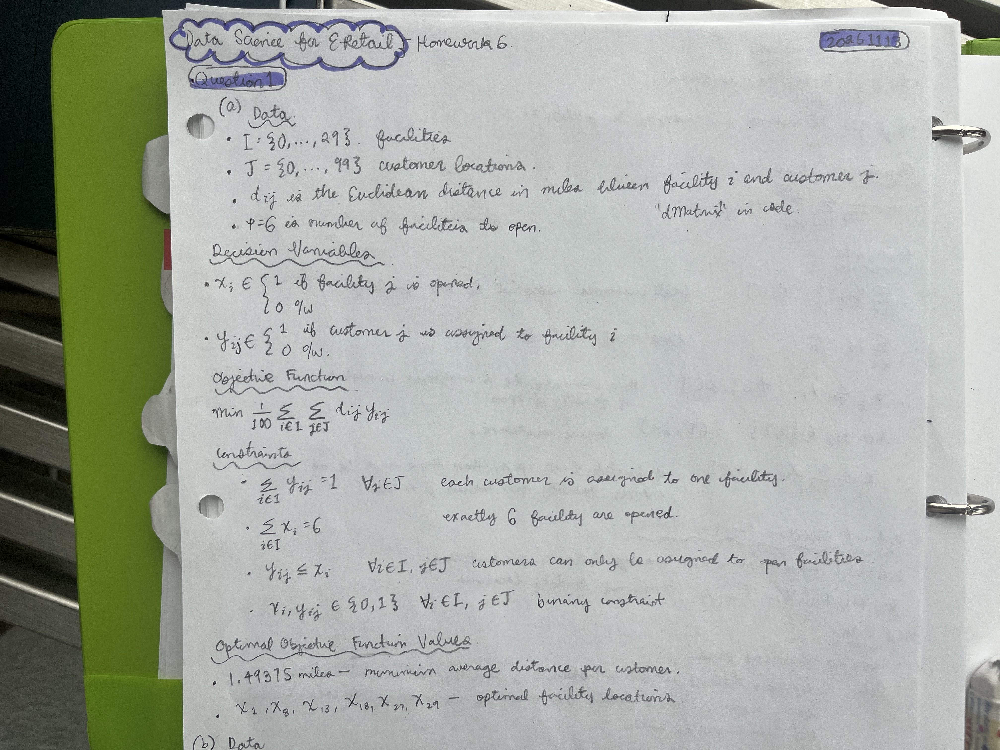

In [172]:
from IPython.display import Image, display
display(Image(filename="hw6_1a.jpeg"))

In [145]:
# License test code from Optimization Methods
# Import the packages needed to run the notebook
import numpy as np
import pandas as pd
import geopandas as gpd
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt
import math

import gurobipy as gp
from gurobipy import *

In [146]:
# License test code from Optimization Methods
# Run this cell to test that your academic license works - you do not need to understand the model or submit anything
# from this cell for the project. If your academic license is **not** setup you will get an error: 
# GurobiError: Model too large for size-limited license
N = 100
c = np.random.rand(N,N)   

m0 = gp.Model('license_test')
x = m0.addVars(N,N, vtype=GRB.BINARY, name="x")     

for n in range(N):
    m0.addConstr(sum(x[n,j] for j in range(N)) == 1, name='row {}'.format(n))
    m0.addConstr(sum(x[i,n] for i in range(N)) == 1, name='col {}'.format(n))

m0.setObjective(sum(c[i,j] * x[i,j] for i in range(N) for j in range(N)), GRB.MINIMIZE)
m0.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 200 rows, 10000 columns and 20000 nonzeros (Min)
Model fingerprint: 0xed69c809
Model has 10000 linear objective coefficients
Variable types: 0 continuous, 10000 integer (10000 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e-05, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Found heuristic solution: objective 44.9070230
Presolve time: 0.01s
Presolved: 200 rows, 10000 columns, 20000 nonzeros
Variable types: 0 continuous, 10000 integer (10000 binary)

Root relaxation: objective 1.607502e+00, 205 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

*    0     0               0

In [147]:
# ---------------------------------------------------------------------------
# INITIALIZATION
# intialized set of potential facility locations i noFacs_ , set of customers locations j noCusts_ , 
#   matrix d_ij which is the distance between facility location i and 
#   customer location j as dMatrix_. 
# bound_ is the limit of the total number of facilities we can open
# ---------------------------------------------------------------------------
def initializeData_a():
    with open("pmedian_data.txt", encoding="utf-8") as file:
        noFacs_, noCusts_ = map(int, file.readline().split())   # converts facility and customer counts to integers
        coordinates = [tuple(map(float, line.split()))          # converts coordinates to tuples
                       for line in file if line.strip()]        

    facilities = coordinates[:noFacs_]  # split coordinates into facility locations
    customers = coordinates[noFacs_:]   # and customer locations

    # builds the 30 x 100 distance matrix with euclidean distances
    dMatrix_ = [
        [math.dist(facilities[i], customers[j])
            for j in range(noCusts_)]
            for i in range(noFacs_)
    ]

    bound_ = 6                 # open 6 facilities 

    return ( noFacs_ , noCusts_ , dMatrix_ , bound_ )

In [148]:
# ---------------------------------------------------------------------------
# CONSTRUCT VARIABLES
# constructed binary variables x_i for each potential facility location i and
#   binary variables y_ij for whether facility location i is connected to customer location j 
# then update model with the variables
# ---------------------------------------------------------------------------

def constructVars_a():
    global ipModel, xVars, yVars

    #.addVars is shortcut and also the binary constraint is defined here
    xVars = ipModel.addVars(noFacs, vtype=GRB.BINARY, name="x") 
    yVars = ipModel.addVars(noFacs, noCusts, vtype=GRB.BINARY, name="y")

    ipModel.update()

In [149]:
# ---------------------------------------------------------------------------
# CONSTRUCT OBJECTION FUNCTION
# constructed objective function to maximize the total population covered 
#   by the selected facilities
# did this by first creating empty expression for objective function, then 
#   adding the product of the population of each customer location and 
#   the corresponding binary variable y_j
# then update the model with the objective function
# ---------------------------------------------------------------------------

def constructObj_a():
    global noCusts , yVars , dMatrix_
    objExpr = LinExpr()
    for i in range ( noFacs ):
        for j in range( noCusts ):
            objExpr += dMatrix_[i][j] * yVars[ i, j ]
    ipModel.setObjective( objExpr / noCusts , GRB.MINIMIZE )
    ipModel.update()

In [150]:
# ---------------------------------------------------------------------------
# CONSTRUCT CONSTRAINTS
# constructed three sets of contraints.
#   the first being the assignment constraints which ensures that  
#       the number of connections between a single customer
#       over all facility locations is 1
#   the second being the cardinality constraint which ensures that 
#       the total number of selected facility locations equals the bound
#   the third being the linking contraint which ensures
#       that a customer can only be connected to a facility which is open (1)
# then update the model with the constraints 
# ---------------------------------------------------------------------------

def constructConsts_a():

    global noFacs , noCusts, ipModel , xVars , yVars , dMatrix , bound

    for j in range( noCusts ):
        constrExpr = LinExpr()  # new expression for each customer 
        for i in range( noFacs ):
            constrExpr += yVars[ i , j ]
        ipModel.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( j ) )
    
    constrExpr = LinExpr()      # one big expression for the whole sum
    for i in range( noFacs ):
        constrExpr += xVars[ i ]
    ipModel.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = bound , name = "cardinality_" + str( bound ) )

    for i in range( noFacs ):
        for j in range( noCusts ):
            ipModel.addLConstr( lhs = yVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = xVars[ i ] , name = "linking_" + str( i ) + "_" + str( j ) )

    ipModel.update()

In [151]:
# ---------------------------------------------------------------------------
# PRINT SOLUTIONS
# print optimal objective value and the values of the decision variables x_i and y_ij
# ---------------------------------------------------------------------------
  
def printSolution_a():
    global noFacs , noCusts , xVars , yVars , ipModel
    print( "Opt. Obj." + str( ipModel.ObjVal ) )
    for i in range( noFacs ):
        print( xVars[ i ].varName + " " + str( xVars[ i ].x ) )
    for j in range( noCusts ):
        print( yVars[ i , j ].varName + " " + str( yVars[ i , j ].x ) )

In [152]:
# ---------------------------------------------------------------------------
# RUNNING COMPUTATION
# returns the initialized data, 
#   constructs the model, 
#   writes the model to a file, 
#   optimizes the model, and 
#   prints the solution
# ---------------------------------------------------------------------------

( noFacs , noCusts , dMatrix_ , bound ) = initializeData_a()
ipModel = gp.Model( "p_median" )
xVars = [ 0 for i in range( noFacs ) ]
yVars = [ 0 for j in range( noCusts ) ]
constructVars_a()
constructObj_a()
constructConsts_a()
ipModel.write( "november_13_2026_a.lp")

In [153]:
# ---------------------------------------------------------------------------
# OPTIMIZE!
# once the .lp file looks good, 
#   optimize the model, and 
#   print the solution
# ---------------------------------------------------------------------------

ipModel.optimize()
printSolution_a()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 3101 rows, 3030 columns and 9030 nonzeros (Min)
Model fingerprint: 0xb45b437d
Model has 3000 linear objective coefficients
Variable types: 0 continuous, 3030 integer (3030 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [9e-04, 1e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+00]

Presolve time: 0.01s
Presolved: 3101 rows, 3030 columns, 9030 nonzeros
Variable types: 0 continuous, 3030 integer (3030 binary)
Found heuristic solution: objective 2.5678882

Root relaxation: objective 1.493751e+00, 571 iterations, 0.01 seconds (0.02 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

*    0     0               0       1

/var/folders/6k/nlcls0s570j_56t476_5msgm0000gn/T/ipykernel_85412/1790731090.py:23: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  matplotlib.pyplot.plot( facilities[ fc ][ 0 ] , facilities[ fc ][ 1 ] , 'ro' ,
/var/folders/6k/nlcls0s570j_56t476_5msgm0000gn/T/ipykernel_85412/1790731090.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  matplotlib.pyplot.plot( customers[ dp ][ 0 ] , customers[ dp ][ 1 ] , 'ro' ,


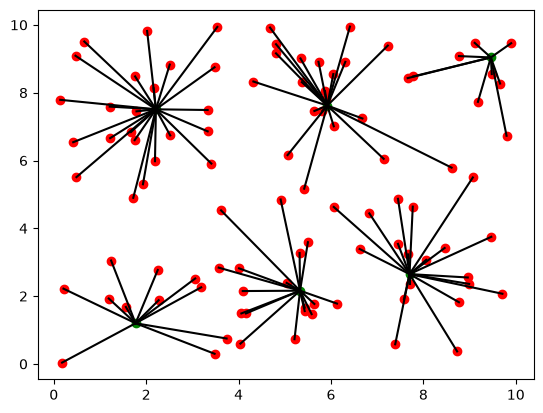

In [154]:
plotPmedianSolution(xVars, yVars)

### (b) If we open a certain facility, then we must have another facility open within 3 miles of the opened facility.
In addition to the model specification in Part a, we want to impose the additional
requirement that if we open a certain facility, then we must have another facility open within 3
miles of the opened facility. Give an integer programming formulation of the problem, solve the
problem by calling Gurobi within a programming language, state the optimal objective function
value and plot the optimal solution.

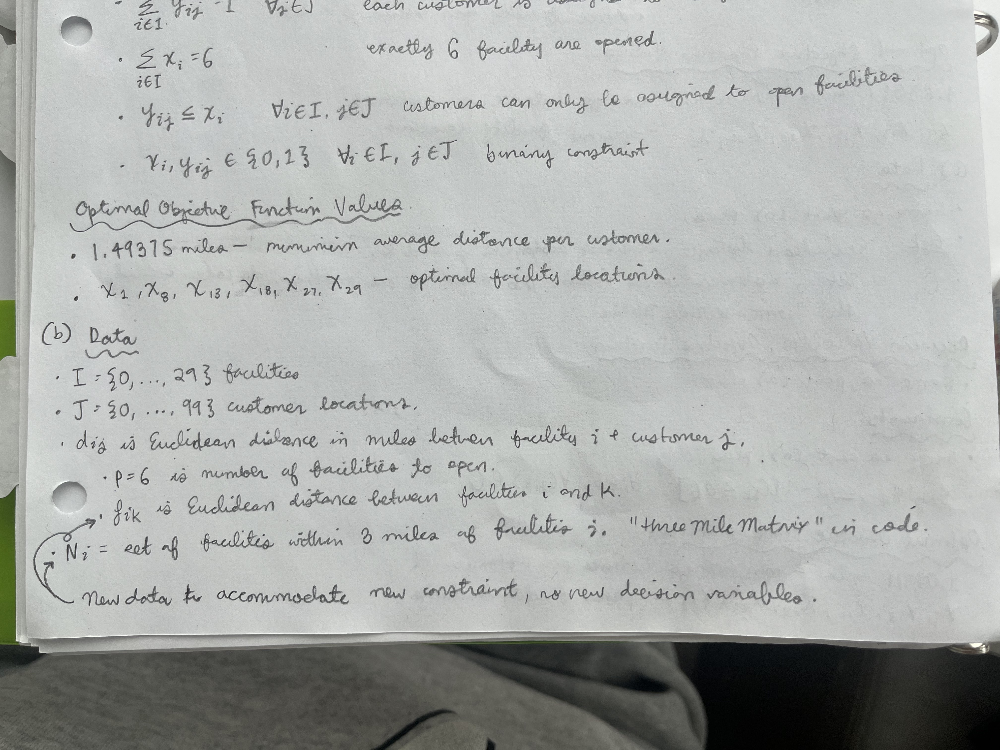

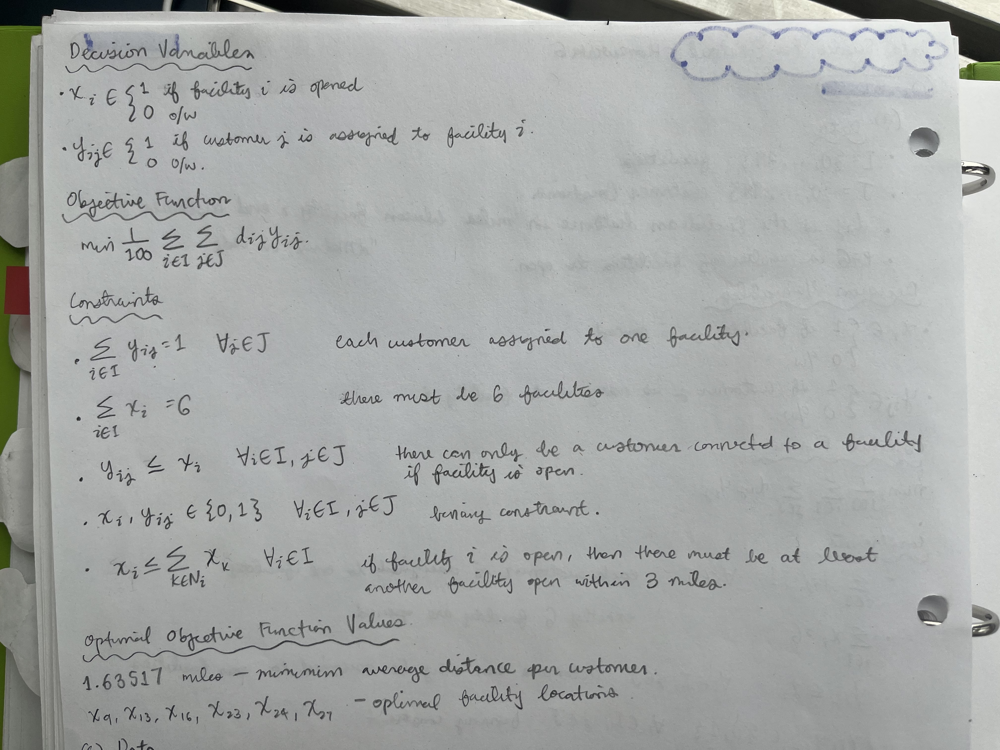

In [173]:
from IPython.display import Image, display
display(Image(filename="hw6_1b1.jpeg"))
display(Image(filename="hw6_1b2.jpeg"))

In [155]:
# ---------------------------------------------------------------------------
# INITIALIZATION
# intialized set of potential facility locations i noFacs_ , set of customers locations j noCusts_ , 
#   matrix d_ij which is the distance between facility location i and 
#   customer location j as dMatrix_. 
# bound_ is the limit of the total number of facilities we can open
# and then 2 matrixes to determine whether facilities are open within 3 miles of one another
#   i'm only using the second of the two matrixes  
# ---------------------------------------------------------------------------
def initializeData_b():
    with open("pmedian_data.txt", encoding="utf-8") as file:
        noFacs_, noCusts_ = map(int, file.readline().split())   # converts facility and customer counts to integers
        coordinates = [tuple(map(float, line.split()))          # converts coordinates to tuples
                       for line in file if line.strip()]        

    facilities = coordinates[:noFacs_]  # split coordinates into facility locations
    customers = coordinates[noFacs_:]   # and customer locations

    # builds the 30 x 100 distance matrix between customers and facilities with euclidean distances
    dMatrix_ = [
        [math.dist(facilities[i], customers[j])
            for j in range(noCusts_)]
            for i in range(noFacs_)
    ]

    bound_ = 6                 # open 6 facilities 

    # builds the 30 x 30 distance matrix between facilities with euclidean distances
    fMatrix_ = [
        [math.dist(facilities[i], facilities[k]) for k in range(noFacs_)]
        for i in range(noFacs_)
    ]

    # another binary matrix that says whether facilities are within 3 miles of the other
    threeMileMatrix_ = [
        [int(i != k and fMatrix_[i][k] <= 3) for k in range(noFacs_)]
        for i in range(noFacs_)
    ] 


    return ( noFacs_ , noCusts_ , dMatrix_ , bound_ , fMatrix_ , threeMileMatrix_ )

In [156]:
# ---------------------------------------------------------------------------
# CONSTRUCT VARIABLES
# constructed binary variables x_i for each potential facility location i and
#   binary variables y_ij for whether facility location i is connected to customer location j 
# then update model with the variables
# ---------------------------------------------------------------------------

def constructVars_b():
    global ipModel, xVars, yVars

    #.addVars is shortcut and also the binary constraint is defined here
    xVars = ipModel.addVars(noFacs, vtype=GRB.BINARY, name="x") 
    yVars = ipModel.addVars(noFacs, noCusts, vtype=GRB.BINARY, name="y")

    ipModel.update()

In [157]:
# ---------------------------------------------------------------------------
# CONSTRUCT OBJECTION FUNCTION
# constructed objective function to maximize the total population covered 
#   by the selected facilities
# did this by first creating empty expression for objective function, then 
#   adding the product of the population of each customer location and 
#   the corresponding binary variable y_j
# then update the model with the objective function
# ---------------------------------------------------------------------------

def constructObj_b():
    global noCusts , yVars , dMatrix_
    objExpr = LinExpr()
    for i in range ( noFacs ):
        for j in range( noCusts ):
            objExpr += dMatrix_[i][j] * yVars[ i, j ]
    ipModel.setObjective( objExpr / noCusts , GRB.MINIMIZE )
    ipModel.update()

In [158]:
# ---------------------------------------------------------------------------
# CONSTRUCT CONSTRAINTS
# constructed three sets of contraints.
#   the first being the assignment constraints which ensures that  
#       the number of connections between a single customer
#       over all facility locations is 1
#   the second being the cardinality constraint which ensures that 
#       the total number of selected facility locations equals the bound
#   the third being the linking contraint which ensures
#       that a customer can only be connected to a facility which is open (1)
#   [new] the fourth being that a facility being open must satisfy the constraint
#       that it is within three miles of at least one other open facility
# then update the model with the constraints 
# ---------------------------------------------------------------------------

def constructConsts_b():

    global noFacs , noCusts, ipModel , xVars , yVars , dMatrix , bound , threeMileMatrix_

    for j in range( noCusts ):
        constrExpr = LinExpr()  # new expression for each customer 
        for i in range( noFacs ):
            constrExpr += yVars[ i , j ]
        ipModel.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( j ) )
    
    constrExpr = LinExpr()      # one big expression for the whole sum
    for i in range( noFacs ):
        constrExpr += xVars[ i ]
    ipModel.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = bound , name = "cardinality_" + str( bound ) )

    for i in range( noFacs ):
        for j in range( noCusts ):
            ipModel.addLConstr( lhs = yVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = xVars[ i ] , name = "linking_" + str( i ) + "_" + str( j ) )

    for i in range( noFacs ):
        constrExpr = LinExpr()
        for k in range(noFacs):
            constrExpr += threeMileMatrix_[i][k] * xVars[k]
        ipModel.addLConstr( lhs=xVars[i], sense=GRB.LESS_EQUAL, rhs=constrExpr, name="neighbor_" + str(i) )
    
    ipModel.update()

In [159]:
# ---------------------------------------------------------------------------
# PRINT SOLUTIONS
# print optimal objective value and the values of the decision variables x_i and y_ij
# ---------------------------------------------------------------------------
  
def printSolution_b():
    global noFacs , noCusts , xVars , yVars , ipModel
    print( "Opt. Obj." + str( ipModel.ObjVal ) )
    for i in range( noFacs ):
        print( xVars[ i ].varName + " " + str( xVars[ i ].x ) )
    for j in range( noCusts ):
        print( yVars[ i , j ].varName + " " + str( yVars[ i , j ].x ) )

In [160]:
# ---------------------------------------------------------------------------
# RUNNING COMPUTATION
# returns the initialized data, 
#   constructs the model, 
#   writes the model to a file, 
#   optimizes the model, and 
#   prints the solution
# ---------------------------------------------------------------------------

( noFacs_ , noCusts_ , dMatrix_ , bound_ , fMatrix_ , threeMileMatrix_ ) = initializeData_b()
ipModel = gp.Model( "3_miles" )
xVars = [ 0 for i in range( noFacs_ ) ]
yVars = [ 0 for j in range( noCusts_ ) ]
constructVars_b()
constructObj_b()
constructConsts_b()
ipModel.write( "november_13_2026_b.lp")

In [161]:
# ---------------------------------------------------------------------------
# OPTIMIZE!
# once the .lp file looks good, 
#   optimize the model, and 
#   print the solution
# ---------------------------------------------------------------------------

ipModel.optimize()
printSolution_b()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 3131 rows, 3030 columns and 9256 nonzeros (Min)
Model fingerprint: 0xd99ed90f
Model has 3000 linear objective coefficients
Variable types: 0 continuous, 3030 integer (3030 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [9e-04, 1e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+00]

Presolve time: 0.01s
Presolved: 3131 rows, 3030 columns, 9256 nonzeros
Variable types: 0 continuous, 3030 integer (3030 binary)
Found heuristic solution: objective 3.5732655

Root relaxation: objective 1.521509e+00, 670 iterations, 0.01 seconds (0.02 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0    1.52151    0   46   

/var/folders/6k/nlcls0s570j_56t476_5msgm0000gn/T/ipykernel_85412/1790731090.py:23: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  matplotlib.pyplot.plot( facilities[ fc ][ 0 ] , facilities[ fc ][ 1 ] , 'ro' ,
/var/folders/6k/nlcls0s570j_56t476_5msgm0000gn/T/ipykernel_85412/1790731090.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  matplotlib.pyplot.plot( customers[ dp ][ 0 ] , customers[ dp ][ 1 ] , 'ro' ,


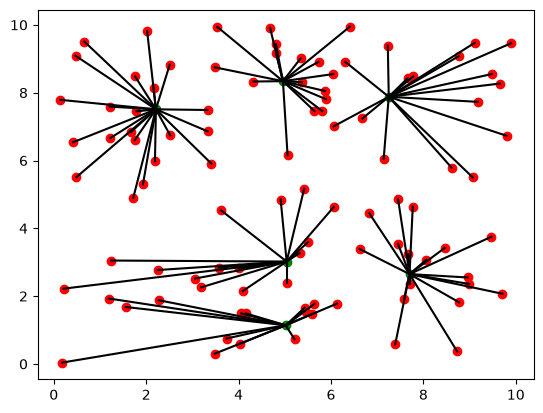

In [162]:
plotPmedianSolution(xVars, yVars)

### (c) If two customer locations are within 0.6 miles of each other, then we cannot assign them to the same facility location
Go back to the model in Part a. In addition to the model specification in Part a, we
want to impose the additional requirement that if two customer locations are within 0.6 miles
of each other, then we cannot assign them to the same facility location. Give an integer
programming formulation of the problem, solve the problem by calling Gurobi within a
programming language, state the optimal objective function value and plot the optimal solution.


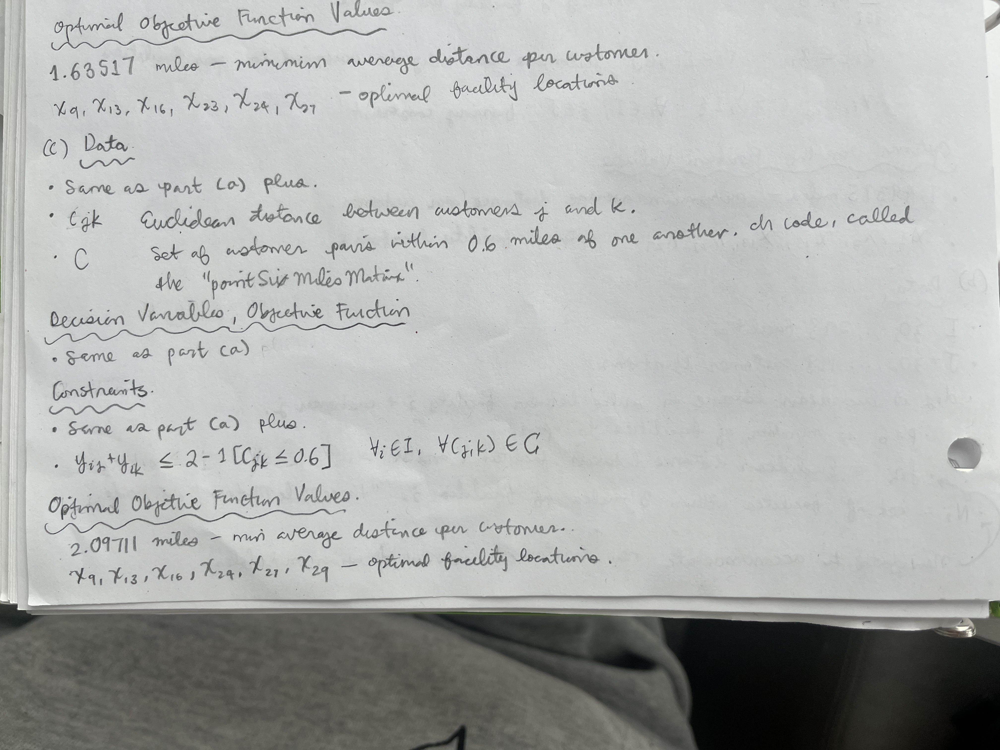

In [174]:
from IPython.display import Image, display
display(Image(filename="hw6_1c.jpeg"))

In [163]:
# ---------------------------------------------------------------------------
# INITIALIZATION
# intialized set of potential facility locations i noFacs_ , set of customers locations j noCusts_ , 
#   matrix d_ij which is the distance between facility location i and 
#   customer location j as dMatrix_. 
# bound_ is the limit of the total number of facilities we can open
# and then 2 matrixes to determine whether facilities are open within 3 miles of one another
#   i'm only using the second of the two matrixes  
# ---------------------------------------------------------------------------
def initializeData_c():
    with open("pmedian_data.txt", encoding="utf-8") as file:
        noFacs_, noCusts_ = map(int, file.readline().split())   # converts facility and customer counts to integers
        coordinates = [tuple(map(float, line.split()))          # converts coordinates to tuples
                       for line in file if line.strip()]        

    facilities = coordinates[:noFacs_]  # split coordinates into facility locations
    customers = coordinates[noFacs_:]   # and customer locations

    # builds the 30 x 100 distance matrix between customers and facilities with euclidean distances
    dMatrix_ = [
        [math.dist(facilities[i], customers[j])
            for j in range(noCusts_)]
            for i in range(noFacs_)
    ]

    bound_ = 6                 # open 6 facilities 

    # builds the 100 x 100 distance matrix between customers with euclidean distances
    cMatrix_ = [
        [math.dist(customers[i], customers[j]) for j in range(noCusts_)]
        for i in range(noCusts_)
    ]

    # another binary matrix that says whether customers are within 0.6 miles of the other
    pointSixMileMatrix_ = [
        [int(i != k and cMatrix_[i][k] <= 0.6) for k in range(noCusts_)]
        for i in range(noCusts_)
    ] 

    
    return ( noFacs_ , noCusts_ , dMatrix_ , bound_ , cMatrix_ , pointSixMileMatrix_ )

In [164]:
# ---------------------------------------------------------------------------
# CONSTRUCT VARIABLES
# constructed binary variables x_i for each potential facility location i and
#   binary variables y_ij for whether facility location i is connected to customer location j 
# then update model with the variables
# ---------------------------------------------------------------------------

def constructVars_c():
    global ipModel, xVars, yVars

    #.addVars is shortcut and also the binary constraint is defined here
    xVars = ipModel.addVars(noFacs_, vtype=GRB.BINARY, name="x") 
    yVars = ipModel.addVars(noFacs_, noCusts_, vtype=GRB.BINARY, name="y")

    ipModel.update()

In [165]:
# ---------------------------------------------------------------------------
# CONSTRUCT OBJECTION FUNCTION
# constructed objective function to maximize the total population covered 
#   by the selected facilities
# did this by first creating empty expression for objective function, then 
#   adding the product of the population of each customer location and 
#   the corresponding binary variable y_j
# then update the model with the objective function
# ---------------------------------------------------------------------------

def constructObj_c():
    global noCusts , yVars , dMatrix_
    objExpr = LinExpr()
    for i in range ( noFacs ):
        for j in range( noCusts ):
            objExpr += dMatrix_[i][j] * yVars[ i, j ]
    ipModel.setObjective( objExpr / noCusts , GRB.MINIMIZE )
    ipModel.update()

In [166]:
# ---------------------------------------------------------------------------
# CONSTRUCT CONSTRAINTS
# constructed three sets of contraints.
#   the first being the assignment constraints which ensures that  
#       the number of connections between a single customer
#       over all facility locations is 1
#   the second being the cardinality constraint which ensures that 
#       the total number of selected facility locations equals the bound
#   the third being the linking contraint which ensures
#       that a customer can only be connected to a facility which is open (1)
#   [new] the fourth being that if a customer is connected to one facility, 
#       it must satisfy the constraint
#       that any customer within 0.6 miles is not assigned to the same facility
# then update the model with the constraints 
# ---------------------------------------------------------------------------

def constructConsts_c():

    global noFacs_ , noCusts_ , ipModel , xVars , yVars , dMatrix_ , bound_ , threeMileMatrix_

    for j in range( noCusts ):
        constrExpr = LinExpr()  # new expression for each customer 
        for i in range( noFacs ):
            constrExpr += yVars[ i , j ]
        ipModel.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( j ) )
    
    constrExpr = LinExpr()      # one big expression for the whole sum
    for i in range( noFacs ):
        constrExpr += xVars[ i ]
    ipModel.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = bound , name = "cardinality_" + str( bound ) )

    for i in range( noFacs ):
        for j in range( noCusts ):
            ipModel.addLConstr( lhs = yVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = xVars[ i ] , name = "linking_" + str( i ) + "_" + str( j ) )

    for i in range(noFacs_):
        for j in range(noCusts_):
            for k in range(j + 1, noCusts_):
                ipModel.addLConstr( lhs=yVars[i, j] + yVars[i, k], sense=GRB.LESS_EQUAL, rhs = 2 - pointSixMileMatrix_[j][k], name="separation_" + str(i) + "_" + str(j) + "_" + str(k) )
    ipModel.update()

In [167]:
# ---------------------------------------------------------------------------
# PRINT SOLUTIONS
# print optimal objective value and the values of the decision variables x_i and y_ij
# ---------------------------------------------------------------------------
  
def printSolution_c():
    global noFacs , noCusts , xVars , yVars , ipModel
    print( "Opt. Obj." + str( ipModel.ObjVal ) )
    for i in range( noFacs ):
        print( xVars[ i ].varName + " " + str( xVars[ i ].x ) )
    for j in range( noCusts ):
        print( yVars[ i , j ].varName + " " + str( yVars[ i , j ].x ) )

In [168]:
# ---------------------------------------------------------------------------
# RUNNING COMPUTATION
# returns the initialized data, 
#   constructs the model, 
#   writes the model to a file, 
#   optimizes the model, and 
#   prints the solution
# ---------------------------------------------------------------------------

( noFacs_ , noCusts_ , dMatrix_ , bound_ , cMatrix_ , pointSixMileMatrix_ ) = initializeData_c()
ipModel = gp.Model( "0.6_miles" )
xVars = [ 0 for i in range( noFacs_ ) ]
yVars = [ 0 for j in range( noCusts_ ) ]
constructVars_c()
constructObj_c()
constructConsts_c()
ipModel.write( "november_13_2026_c.lp")

In [169]:
# ---------------------------------------------------------------------------
# OPTIMIZE!
# once the .lp file looks good, 
#   optimize the model, and 
#   print the solution
# ---------------------------------------------------------------------------

ipModel.optimize()
printSolution_c()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 151601 rows, 3030 columns and 306030 nonzeros (Min)
Model fingerprint: 0x94b92a92
Model has 3000 linear objective coefficients
Variable types: 0 continuous, 3030 integer (3030 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [9e-04, 1e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+00]

Presolve removed 147090 rows and 0 columns
Presolve time: 0.01s
Presolved: 4511 rows, 3030 columns, 11850 nonzeros
Variable types: 0 continuous, 3030 integer (3030 binary)
Found heuristic solution: objective 3.1857228
Performing another presolve...
Presolve removed 2190 rows and 0 columns
Presolve time: 0.01s

Root relaxation: objective 2.097105e+00, 1166 iterations, 0.01 seconds (0.03 work units)

    Nodes    |    Current Node    |     Objec

/var/folders/6k/nlcls0s570j_56t476_5msgm0000gn/T/ipykernel_85412/1790731090.py:23: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  matplotlib.pyplot.plot( facilities[ fc ][ 0 ] , facilities[ fc ][ 1 ] , 'ro' ,
/var/folders/6k/nlcls0s570j_56t476_5msgm0000gn/T/ipykernel_85412/1790731090.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  matplotlib.pyplot.plot( customers[ dp ][ 0 ] , customers[ dp ][ 1 ] , 'ro' ,


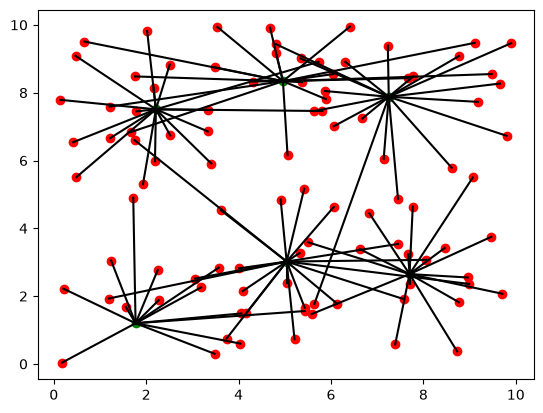

In [175]:
plotPmedianSolution(xVars, yVars)

### (d) Academic Integrity
Both your team members should write and sign the following pledge: “Academic
integrity is expected of all students of Cornell University at all times, whether in the presence or
absence of members of the faculty. Understanding this, I declare that all of the team members
contributed equally to all stages of this homework assignment.”

Academic
integrity is expected of all students of Cornell University at all times, whether in the presence or
absence of members of the faculty. Understanding this, I declare that all of the team members
contributed equally to all stages of this homework assignment.